## Jointure des tables Olist

Fusion des 9 fichiers en un tableau par commande. La cible par défaut est `late_delivery` (livraison en retard). Les colonnes connues seulement après la commande (dates de livraison, note d'avis) ne sont pas utilisées comme features.

In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [21]:
DATA_DIR = Path("../Data/version/2")

In [22]:
def load(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", encoding="utf-8-sig")

In [23]:
orders = load("dataset1")
customers = load("dataset2")
items = load("dataset3")
products = load("dataset4")
categories = load("dataset5")
payments = load("dataset6")
reviews = load("dataset7")

In [55]:
payments


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [51]:
reviews["product_category_name"].value_counts()

product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64

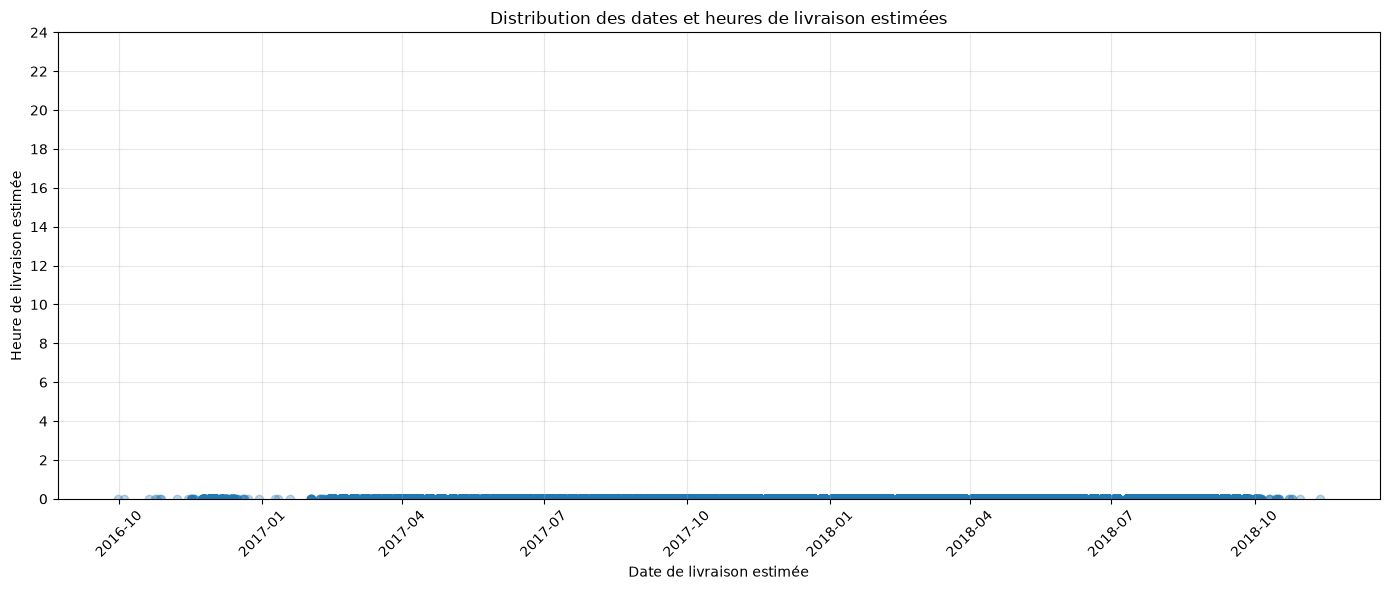

In [46]:

import pandas as pd
import matplotlib.pyplot as plt

# Convertir la colonne en datetime
payments["order_estimated_delivery_date"] = pd.to_datetime(
    payments["order_estimated_delivery_date"],
    errors="coerce"
)

# Supprimer les dates manquantes
data = payments.dropna(subset=["order_estimated_delivery_date"]).copy()

# Extraire la date et l'heure
data["date"] = data["order_estimated_delivery_date"].dt.date
data["heure"] = (
    data["order_estimated_delivery_date"].dt.hour
    + data["order_estimated_delivery_date"].dt.minute / 60
)

# Tracer le graphique
plt.figure(figsize=(14, 6))

plt.scatter(
    data["date"],
    data["heure"],
    alpha=0.3
)

plt.xlabel("Date de livraison estimée")
plt.ylabel("Heure de livraison estimée")
plt.title("Distribution des dates et heures de livraison estimées")

plt.yticks(range(0, 25, 2))
plt.ylim(0, 24)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



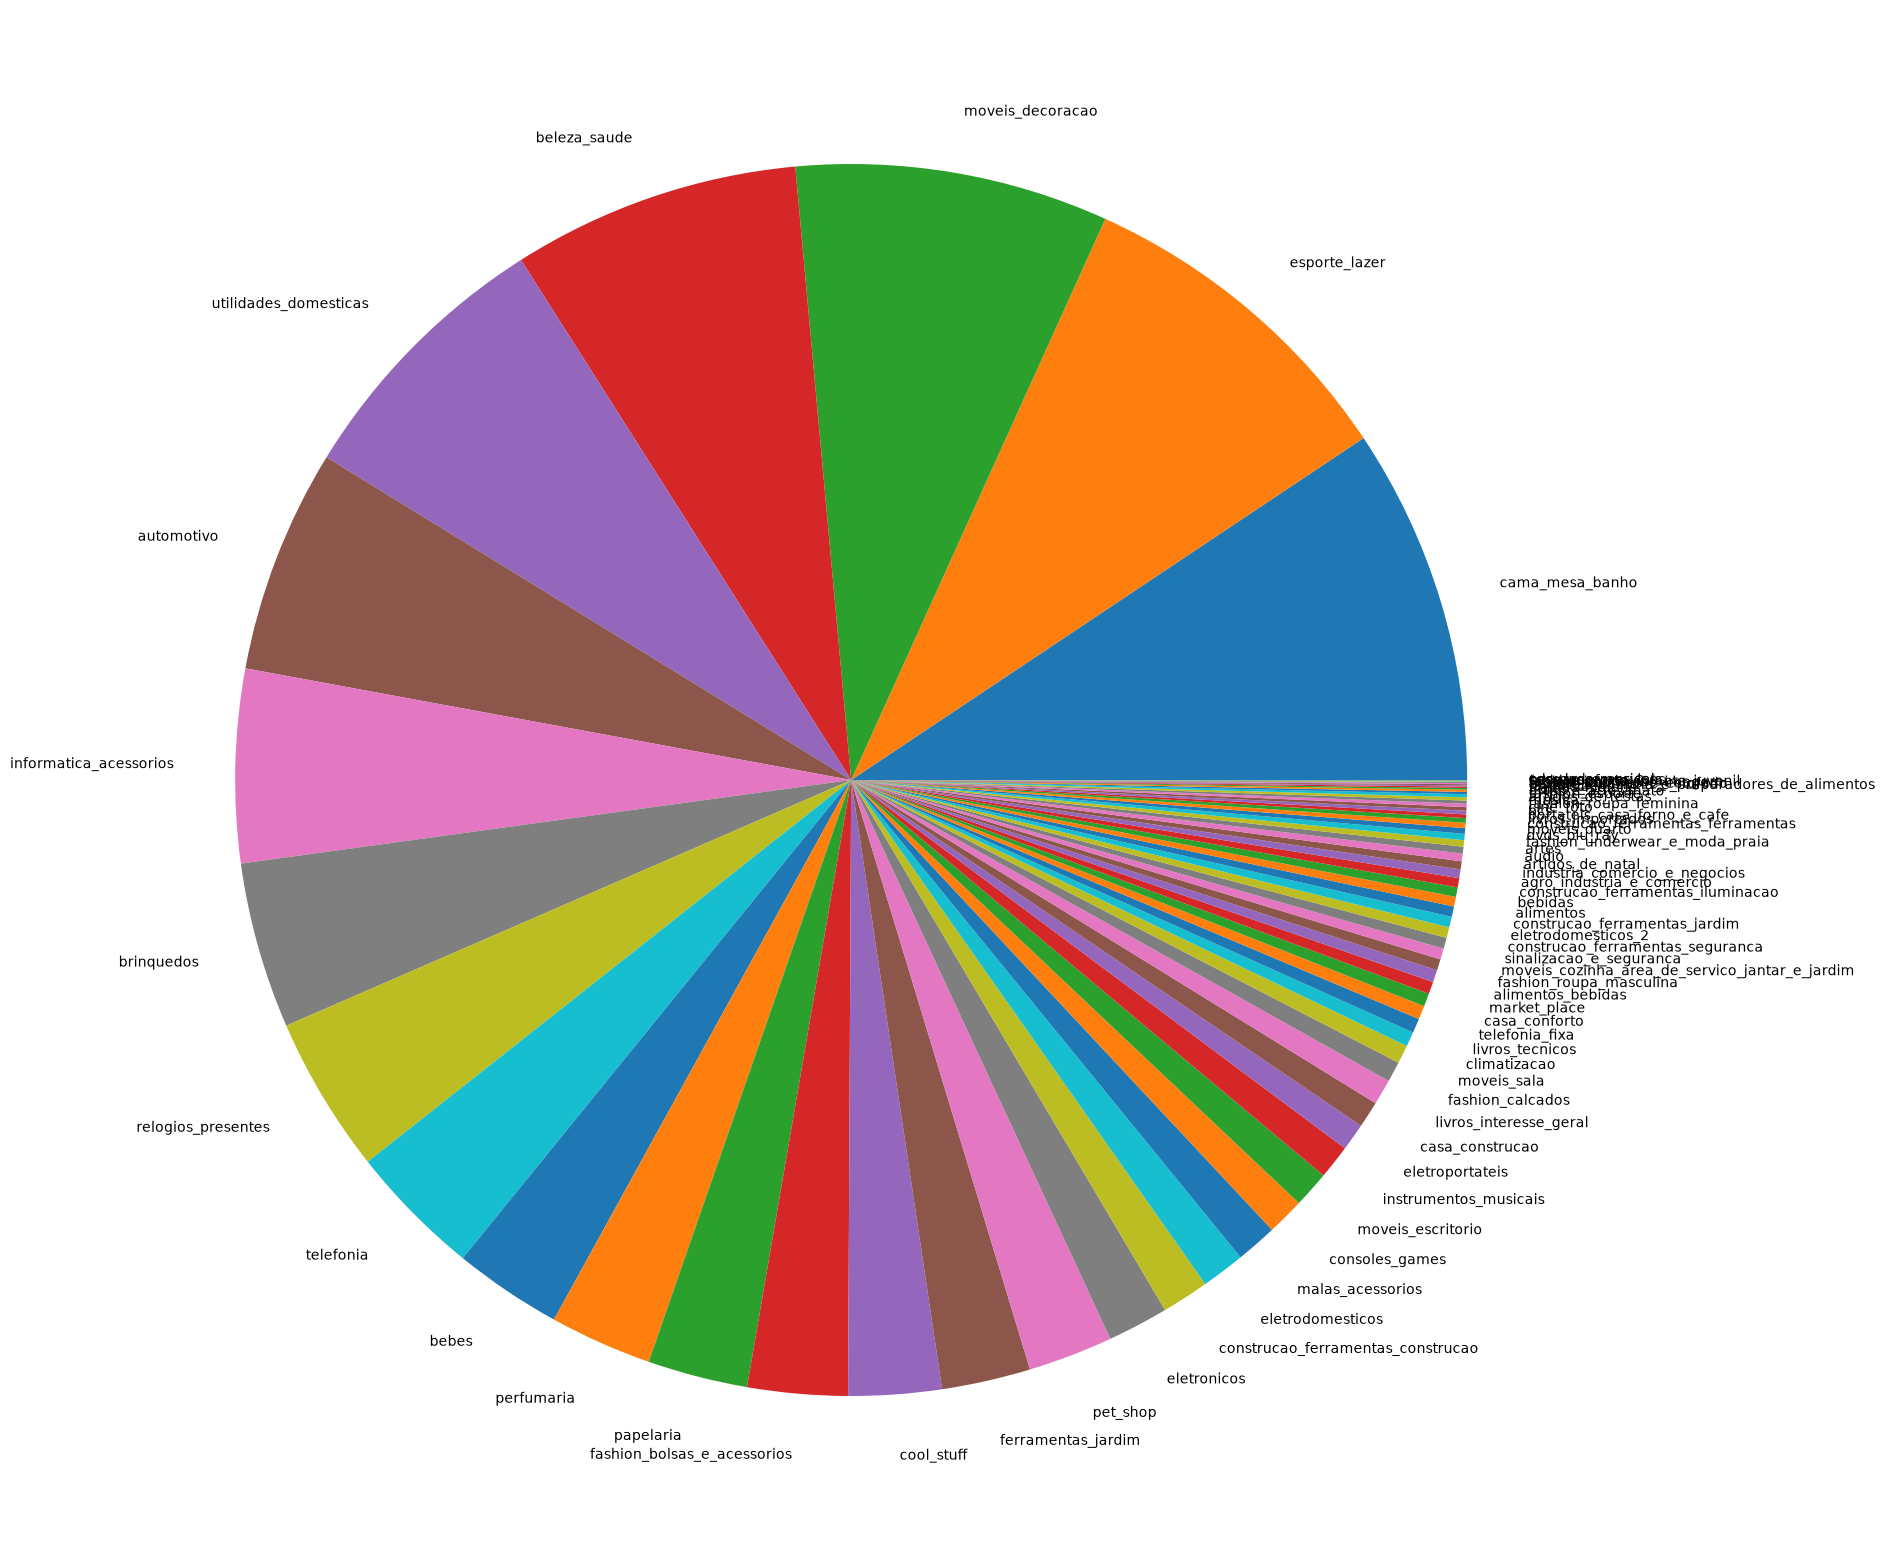

In [64]:
reviews["product_category_name"].value_counts().plot(figsize=(20,20), kind="pie", color="purple")
plt.show()

In [ ]:
cout = reviews.value_counts()

<Axes: title={'center': 'Review Type Distribution'}, xlabel='Review Type', ylabel='Count'>

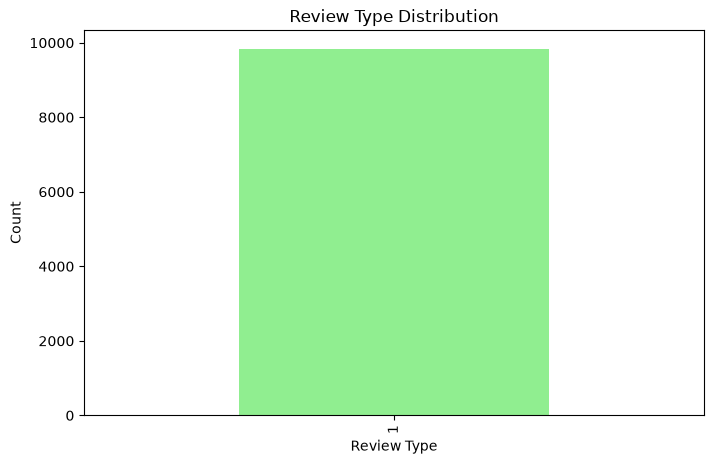

In [ ]:
review_counts = cout.value_counts()
review_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color="lightgreen",
    xlabel="Review Type",
    ylabel="Count",
    title="Review Type Distribution",
)   

In [ ]:
payment_counts

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [ ]:
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [ ]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)

In [ ]:

items_full = (
    items
    .merge(products, on="product_id", how="left")
    .merge(categories, on="product_category_name", how="left")
)

In [ ]:
items_agg = items_full.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
    n_sellers=("seller_id", "nunique"),
    first_category=("product_category_name_english", "first"),
).reset_index()

In [ ]:
payments_agg = payments.groupby("order_id").agg(
    n_payments=("payment_sequential", "count"),
    payment_value=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
).reset_index()

reviews_agg = reviews.groupby("order_id", as_index=False).agg(review_score=("review_score", "mean"))

In [ ]:
payments_agg

,order_id,n_payments,payment_value,max_installments
0,00010242fe8c5a6d1ba2dd792cb16214,1,72.19,2
1,00018f77f2f0320c557190d7a144bdd3,1,259.83,3
2,000229ec398224ef6ca0657da4fc703e,1,216.87,5
3,00024acbcdf0a6daa1e931b038114c75,1,25.78,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,218.04,3
...,...,...,...,...
99435,fffc94f6ce00a00581880bf54a75a037,1,343.40,1
99436,fffcd46ef2263f404302a634eb57f7eb,1,386.53,1
99437,fffce4705a9662cd70adb13d4a31832d,1,116.85,3
99438,fffe18544ffabc95dfada21779c9644f,1,64.71,3


In [ ]:
df = (
    orders
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
    .merge(items_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
    .merge(reviews_agg, on="order_id", how="left")
)
print(df.shape)


(99441, 19)


In [ ]:
df.shape

(99441, 19)

In [ ]:
delivered = (
    df[df["order_status"] == "delivered"]
    .dropna(subset=["order_delivered_customer_date", "order_estimated_delivery_date"])
    .copy()
)

delivered["late_delivery"] = (
    delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]
).astype(int)

delivered["promised_days"] = (
    delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]
).dt.days
delivered["purchase_month"] = delivered["order_purchase_timestamp"].dt.month
delivered["purchase_dow"] = delivered["order_purchase_timestamp"].dt.dayofweek




(96470, 13) (96470,)
late_delivery
0    0.919
1    0.081
Name: proportion, dtype: float64


In [ ]:
delivered.shape
delivered.to_csv("../Data/dataset_clean.csv", index=False)

In [ ]:
features = [
    "n_items", "total_price", "total_freight", "total_weight_g", "n_sellers",
    "first_category", "customer_state",
    "n_payments", "payment_value", "max_installments",
    "promised_days", "purchase_month", "purchase_dow",
]
X = delivered[features]
y = delivered["late_delivery"]

print(X.shape, y.shape)
print(y.value_counts(normalize=True).round(3))

NameError: name 'delivered' is not defined

In [ ]:
X

,n_items,total_price,total_freight,total_weight_g,n_sellers,first_category,customer_state,n_payments,payment_value,max_installments,promised_days,purchase_month,purchase_dow
0,1.0,29.99,8.72,500.0,1.0,housewares,SP,3.0,38.71,1.0,15,10,0
1,1.0,118.70,22.76,400.0,1.0,perfumery,BA,1.0,141.46,1.0,19,7,1
2,1.0,159.90,19.22,420.0,1.0,auto,GO,1.0,179.12,3.0,26,8,2
3,1.0,45.00,27.20,450.0,1.0,pet_shop,RN,1.0,72.20,1.0,26,11,5
4,1.0,19.90,8.72,250.0,1.0,stationery,SP,1.0,28.62,1.0,12,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,1.0,72.00,13.08,1175.0,1.0,health_beauty,SP,1.0,85.08,3.0,18,3,3
99437,1.0,174.90,20.10,4950.0,1.0,baby,SP,1.0,195.00,3.0,23,2,1
99438,1.0,205.99,65.02,13300.0,1.0,home_appliances_2,BA,1.0,271.01,5.0,30,8,6
99439,2.0,359.98,81.18,13100.0,1.0,computers_accessories,RJ,1.0,441.16,4.0,37,1,0


NameError: name 'X' is not defined